<a href="https://colab.research.google.com/github/The-Harsh-07/ML-CIE-1-Activity-AD3121/blob/main/unit%201/ML_CIE_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import OneHotEncoder, StandardScaler

In [3]:
df_raw = sns.load_dataset('titanic')

print("--- Step 2: Load and Inspect ---\n")
print("First 3 rows:\n", df_raw.head(3))
print("\nLast 3 rows:\n", df_raw.tail(3))
print(f"\nShape: {df_raw.shape[0]} rows, {df_raw.shape[1]} columns")
print("\nData Types:\n", df_raw.dtypes)

--- Step 2: Load and Inspect ---

First 3 rows:
    survived  pclass     sex   age  sibsp  parch     fare embarked  class  \
0         0       3    male  22.0      1      0   7.2500        S  Third   
1         1       1  female  38.0      1      0  71.2833        C  First   
2         1       3  female  26.0      0      0   7.9250        S  Third   

     who  adult_male deck  embark_town alive  alone  
0    man        True  NaN  Southampton    no  False  
1  woman       False    C    Cherbourg   yes  False  
2  woman       False  NaN  Southampton   yes   True  

Last 3 rows:
      survived  pclass     sex   age  sibsp  parch   fare embarked  class  \
888         0       3  female   NaN      1      2  23.45        S  Third   
889         1       1    male  26.0      0      0  30.00        C  First   
890         0       3    male  32.0      0      0   7.75        Q  Third   

       who  adult_male deck  embark_town alive  alone  
888  woman       False  NaN  Southampton    no  False 

In [5]:
numerical_cols = df_raw.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_cols = df_raw.select_dtypes(include=['object', 'category', 'bool']).columns.tolist()

print("\n--- Step 3: Data Types & Statistics ---\n")
print("Numerical columns:", numerical_cols)
print("Categorical columns:", categorical_cols)
print("\nSummary Statistics (Numerical):\n", df_raw[numerical_cols].describe())


--- Step 3: Data Types & Statistics ---

Numerical columns: ['survived', 'pclass', 'age', 'sibsp', 'parch', 'fare']
Categorical columns: ['sex', 'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town', 'alive', 'alone']

Summary Statistics (Numerical):
          survived      pclass         age       sibsp       parch        fare
count  891.000000  891.000000  714.000000  891.000000  891.000000  891.000000
mean     0.383838    2.308642   29.699118    0.523008    0.381594   32.204208
std      0.486592    0.836071   14.526497    1.102743    0.806057   49.693429
min      0.000000    1.000000    0.420000    0.000000    0.000000    0.000000
25%      0.000000    2.000000   20.125000    0.000000    0.000000    7.910400
50%      0.000000    3.000000   28.000000    0.000000    0.000000   14.454200
75%      1.000000    3.000000   38.000000    1.000000    0.000000   31.000000
max      1.000000    3.000000   80.000000    8.000000    6.000000  512.329200


In [6]:
print("\n--- Step 4: Missing Values ---\n")
missing_counts = df_raw.isnull().sum()
missing_percentages = (missing_counts / len(df_raw)) * 100
missing_df = pd.DataFrame({'Count': missing_counts, 'Percentage': missing_percentages})
print(missing_df[missing_df['Count'] > 0])



--- Step 4: Missing Values ---

             Count  Percentage
age            177   19.865320
embarked         2    0.224467
deck           688   77.216611
embark_town      2    0.224467


In [7]:
df_clean = df_raw.copy()

In [12]:
df_clean.drop(columns=['deck'], inplace=True, errors='ignore')
df_clean['age'] = df_clean['age'].fillna(df_clean['age'].median())
mode_embarked = df_clean['embarked'].mode()[0]
mode_embark_town = df_clean['embark_town'].mode()[0]
df_clean['embarked'] = df_clean['embarked'].fillna(mode_embarked)
df_clean['embark_town'] = df_clean['embark_town'].fillna(mode_embark_town)
print("\n--- Step 5: Handling Missing Values ---\n")
print("Remaining missing values:\n", df_clean.isnull().sum().sum())


--- Step 5: Handling Missing Values ---

Remaining missing values:
 0


In [17]:
duplicates_count = df_clean.duplicated().sum()
print("\n--- Step 6: Duplicates & Consistency ---\n")
print(f"Initial duplicate rows: {duplicates_count}")

df_clean['sex'] = df_clean['sex'].str.lower().str.strip()
df_clean['embark_town'] = df_clean['embark_town'].str.lower().str.strip()


--- Step 6: Duplicates & Consistency ---

Initial duplicate rows: 116


In [18]:
print("\n--- Step 7: Exploratory Data Analysis ---\n")
print("Frequency counts for 'embark_town':\n", df_clean['embark_town'].value_counts())


--- Step 7: Exploratory Data Analysis ---

Frequency counts for 'embark_town':
 embark_town
southampton    646
cherbourg      168
queenstown      77
Name: count, dtype: int64


Text(0, 0.5, 'Frequency')

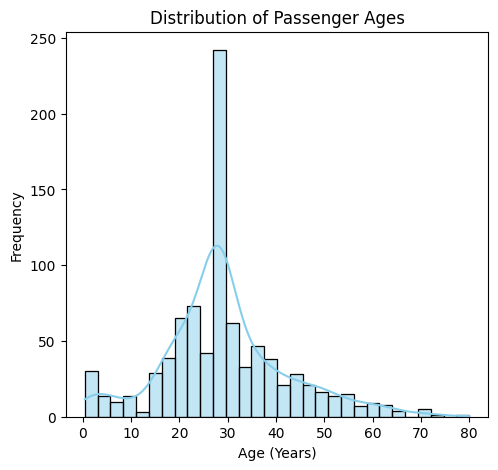

In [19]:
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.histplot(df_clean['age'], bins=30, kde=True, color='skyblue')
plt.title("Distribution of Passenger Ages")
plt.xlabel("Age (Years)")
plt.ylabel("Frequency")

/tmp/ipykernel_2081/1620281596.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='pclass', y='survived', data=df_clean, palette='muted', errorbar=None)


Text(0, 0.5, 'Survival Rate')

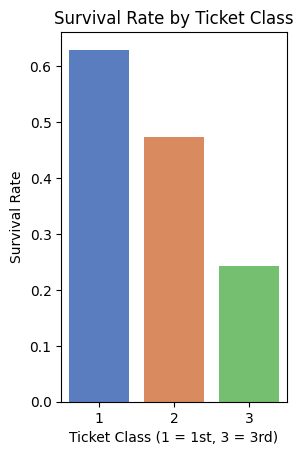

In [20]:
plt.subplot(1, 2, 2)
sns.barplot(x='pclass', y='survived', data=df_clean, palette='muted', errorbar=None)
plt.title("Survival Rate by Ticket Class")
plt.xlabel("Ticket Class (1 = 1st, 3 = 3rd)")
plt.ylabel("Survival Rate")

In [23]:
df_clean.drop(columns=['alive', 'class', 'embark_town', 'who', 'adult_male'], inplace=True)

In [24]:
print("\n--- Step 8: Encoding ---\n")
print("Features before encoding:", df_clean.columns.tolist())

df_encoded = pd.get_dummies(df_clean, columns=['sex', 'embarked'], drop_first=True)

print("Features after encoding:", df_encoded.columns.tolist())


--- Step 8: Encoding ---

Features before encoding: ['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'alone']
Features after encoding: ['survived', 'pclass', 'age', 'sibsp', 'parch', 'fare', 'alone', 'sex_male', 'embarked_Q', 'embarked_S']


In [25]:
scaler = StandardScaler()
cols_to_scale = ['age', 'fare']
df_encoded[cols_to_scale] = scaler.fit_transform(df_encoded[cols_to_scale])

print("\n--- Step 9: Scaling ---\n")
print("Scaled 'age' and 'fare' using StandardScaler (Mean=0, Variance=1).")
print(df_encoded[['age', 'fare']].head(3))


--- Step 9: Scaling ---

Scaled 'age' and 'fare' using StandardScaler (Mean=0, Variance=1).
        age      fare
0 -0.565736 -0.502445
1  0.663861  0.786845
2 -0.258337 -0.488854


In [26]:
print("\n--- Step 10: Verification and Saving ---\n")
print(f"Final shape: {df_encoded.shape}")
print(f"Remaining missing values: {df_encoded.isnull().sum().sum()}")


--- Step 10: Verification and Saving ---

Final shape: (891, 10)
Remaining missing values: 0


In [27]:
file_name = "cleaned_titanic_prepared.csv"
df_encoded.to_csv(file_name, index=False)

print(f"\nDataset successfully saved to: {file_name}")
print("\nFinal Data Sample:\n", df_encoded.head(3))


Dataset successfully saved to: cleaned_titanic_prepared.csv

Final Data Sample:
    survived  pclass       age  sibsp  parch      fare  alone  sex_male  \
0         0       3 -0.565736      1      0 -0.502445  False      True   
1         1       1  0.663861      1      0  0.786845  False     False   
2         1       3 -0.258337      0      0 -0.488854   True     False   

   embarked_Q  embarked_S  
0       False        True  
1       False       False  
2       False        True  
